# The cascade at the neutrino vertex — read directly from the raw ROOT files

This notebook reads **only** the two ROOT files below and computes everything itself. It does not
import anything from `data_manager/energy_truth/`, does not use the HDF5 files and does not use
any cached extraction.

| production | file | `fDate` |
|---|---|---|
| `nu2_100pev` (astrophysical ν_μ, E⁻²) | `demo_root/nue2_1000.root` | 231018 |
| `nuatm` (atmospheric ν_μ) | `demo_root/nuatm_1000.root` | 220119 |

`BMCEvent.fTracks.fInteractions` is a `TClonesArray` of the custom class `BMCInteraction`, so its
leaves cannot be read by `uproot` (checked: the branch is listed but its members are not
accessible). `TTree::Draw(..., "goff")` exposes them as flat arrays, and that is what is used here.

For every **sentinel** track (`fMuonEnergy == -0.001`, i.e. the muon is born downstream of the
reference point) the distance along the track between each cascade and the muon's birth point is

```
d   = (sinθcosφ, sinθsinφ, cosθ)          from fTracks.fTheta, fTracks.fPhi
s   = (cascade_xyz − fTracks.fX/fY/fZ)·d  metres along the track from the reference point
s_v = −c·fFirstMuonTime                   the birth point
Δs  = s − s_v
```
> **How to run.** This machine has no PyROOT in `baikal25`, so ROOT 6.40.04 is installed in a
> separate conda env:
> ```
> conda run -n rootcheck jupyter nbconvert --to notebook --execute --inplace vertex_cascade_check.ipynb
> ```
> or open the notebook and pick the `rootcheck` kernel. `baikal25` is untouched.


In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ROOT

ROOT.gErrorIgnoreLevel = ROOT.kFatal
HERE = Path.cwd()
FILES = {"nue2": HERE / "demo_root/nue2_1000.root",
         "nuatm": HERE / "demo_root/nuatm_1000.root"}
C_LIGHT = 0.299792458
COLOR = {"nue2": "#2a78d6", "nuatm": "#eb6834"}
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e5e4e0", "#fcfcfb"

BRANCHES = {
    "e_nu":      "BMCEvent.fPrimaryParticleEnergy",
    "t_first":   "BMCEvent.fFirstMuonTime",
    "reg":       "BMCEvent.fSumEnergyBundleReg",
    "e_mu":      "BMCEvent.fTracks.fMuonEnergy",
    "n_tracks":  "BMCEvent.fResponseMuonsN",
    "theta":     "BMCEvent.fTracks.fTheta",
    "phi":       "BMCEvent.fTracks.fPhi",
    "ref_x":     "BMCEvent.fTracks.fX",
    "ref_y":     "BMCEvent.fTracks.fY",
    "ref_z":     "BMCEvent.fTracks.fZ",
    "n_casc":    "BMCEvent.fTracks.fInteractionN",
    "casc_e":    "BMCEvent.fTracks.fInteractions.fEnergy",
    "casc_x":    "BMCEvent.fTracks.fInteractions.fX",
    "casc_y":    "BMCEvent.fTracks.fInteractions.fY",
    "casc_z":    "BMCEvent.fTracks.fInteractions.fZ",
}

def draw(tree, expression, n_entries):
    n = tree.Draw(expression, "", "goff", n_entries, 0)
    if n < 0:
        raise RuntimeError(f"Draw failed: {expression}")
    return np.frombuffer(tree.GetV1(), dtype=np.float64, count=n).copy()

def read_file(path):
    tf = ROOT.TFile.Open(str(path))
    tree = tf.Get("Events")
    n = int(tree.GetEntries())
    tree.SetEstimate(max(n * 300, 1_000_000))
    out = {name: draw(tree, expr, n) for name, expr in BRANCHES.items()}
    tf.Close()
    out["n_entries"] = n
    return out

In [2]:
def gaps(a):
    n_casc = a["n_casc"].astype(int)
    # the declared cascade count must equal the number of array elements actually returned
    assert n_casc.sum() == len(a["casc_e"]), "Draw returned a different number of cascades"
    starts = np.concatenate([[0], np.cumsum(n_casc)]).astype(int)

    selected = np.flatnonzero((np.isclose(a["e_mu"], -1e-3, atol=1e-9)) &
                              (a["n_tracks"] == 1) & (n_casc > 0))
    deltas = []
    for i in selected:
        th, ph = np.radians(a["theta"][i]), np.radians(a["phi"][i])
        d = np.array([np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)])
        lo, hi = starts[i], starts[i] + n_casc[i]
        pts = np.stack([a["casc_x"][lo:hi], a["casc_y"][lo:hi], a["casc_z"][lo:hi]], axis=1)
        ref = np.array([a["ref_x"][i], a["ref_y"][i], a["ref_z"][i]])
        deltas.append((pts - ref) @ d - (-C_LIGHT * a["t_first"][i]))
    return selected, deltas

data = {}
for name, path in FILES.items():
    a = read_file(path)
    sel, deltas = gaps(a)
    data[name] = (a, sel, deltas)
    print(f"{name}: {a['n_entries']:,} entries in the file, {len(sel):,} sentinel single-track "
          f"events with cascades, {sum(len(x) for x in deltas):,} cascades")
    print(f"   declared cascade count vs elements read: "
          f"{a['n_casc'].sum():.0f} vs {len(a['casc_e'])}  -> "
          f"{'OK' if a['n_casc'].sum() == len(a['casc_e']) else 'MISMATCH'}")

nue2: 21,523 entries in the file, 3,255 sentinel single-track events with cascades, 7,545 cascades
   declared cascade count vs elements read: 151712 vs 151712  -> OK
nuatm: 39,547 entries in the file, 5,050 sentinel single-track events with cascades, 7,099 cascades
   declared cascade count vs elements read: 36710 vs 36710  -> OK


In [3]:
data

{'nue2': ({'e_nu': array([   599.73687744,    956.36450195,  17582.14257812, ...,
          235894.109375  ,   3114.16943359,  33189.3671875 ], shape=(21523,)),
   't_first': array([-292.35098267,  533.77441406, 1521.29040527, ..., 1724.8302002 ,
          1711.16564941, 2054.76733398], shape=(21523,)),
   'reg': array([  256.35986328,   458.41619873,  2755.53979492, ...,
          90040.7734375 ,  1361.41882324,  1230.32800293], shape=(21523,)),
   'e_mu': array([-1.00000005e-03,  3.99748871e+02,  2.41718921e+03, ...,
           8.49042188e+04,  1.08679626e+03,  9.05799744e+02], shape=(21523,)),
   'n_tracks': array([1., 1., 1., ..., 1., 1., 1.], shape=(21523,)),
   'theta': array([54.01125336, 83.55508423, 39.93125916, ..., 73.36089325,
           8.57862854, 20.03234863], shape=(21523,)),
   'phi': array([152.26397705, 103.17724609,  74.38690186, ..., 322.00747681,
          237.21266174, 117.48300171], shape=(21523,)),
   'ref_x': array([  43.94484329,  -37.01955795,  364.06893921,

In [3]:
print(f"{'production':>8s} {'events':>7s} | " +
      " ".join(f"{'< ' + f'{t:.0e}':>8s}" for t in (1e-9, 1e-6, 1e-3, 1e-2, 1e-1)) +
      f" | {'closest, m':>12s} {'median, m':>10s}")
for name, (a, sel, deltas) in data.items():
    closest = np.array([np.abs(x).min() for x in deltas])
    row = " ".join(f"{100 * np.mean(closest < t):7.1f}%" for t in (1e-9, 1e-6, 1e-3, 1e-2, 1e-1))
    print(f"{name:>8s} {len(sel):>7,} | {row} | {closest.min():>12.3g} {np.median(closest):>10.3g}")

production  events |  < 1e-09  < 1e-06  < 1e-03  < 1e-02  < 1e-01 |   closest, m  median, m
    nue2   3,255 |     0.0%     9.3%    97.0%    97.0%    97.0% |     7.45e-10   6.85e-06
   nuatm   5,050 |     0.0%     0.0%     0.0%     0.0%     0.1% |      0.00576       43.2


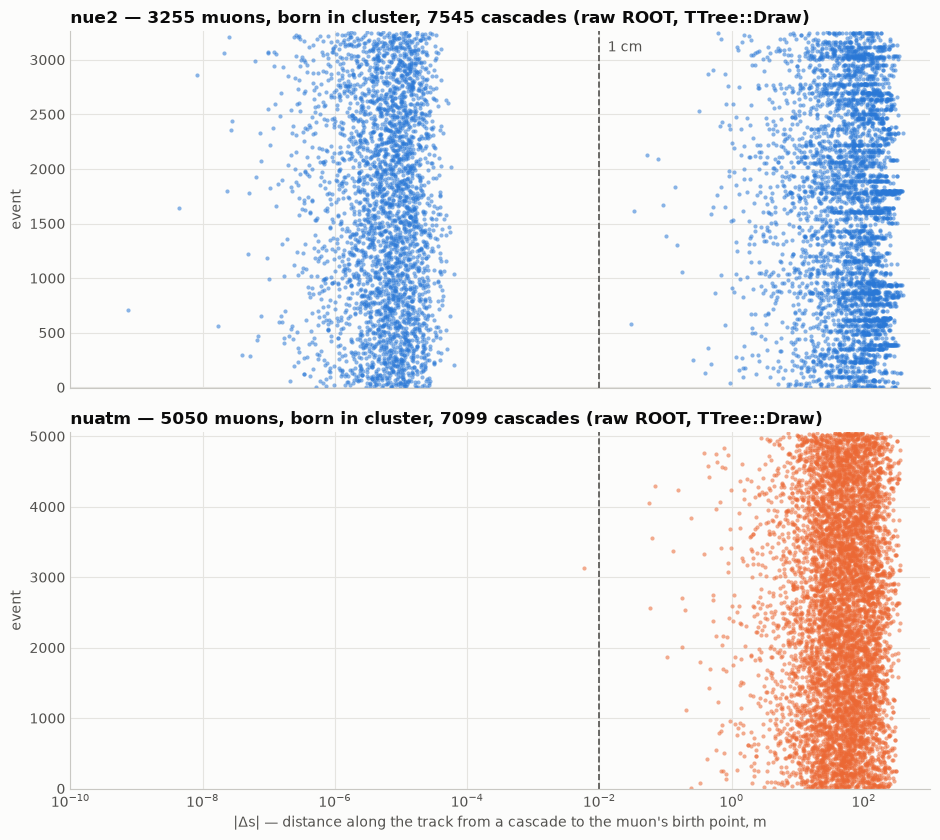

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(9.5, 8.5), sharex=True)
fig.patch.set_facecolor(SURFACE)

for ax, (name, (a, sel, deltas)) in zip(axes, data.items()):
    xs = np.concatenate([np.abs(x) for x in deltas])
    ys = np.repeat(np.arange(len(deltas)), [len(x) for x in deltas])
    ax.set_facecolor(SURFACE)
    ax.scatter(xs, ys, s=9, color=COLOR[name], alpha=0.55, linewidths=0)
    ax.axvline(1e-2, color=MUTED, linestyle="--", linewidth=1.2)
    ax.set_xscale("log")
    ax.set_xlim(1e-10, 1e3)
    ax.set_ylim(-5, len(deltas) + 5)
    ax.set_ylabel("event", color=MUTED)
    ax.set_title(f"{name} — {len(deltas)} muons, born in cluster, {len(xs)} cascades "
                 f"(raw ROOT, TTree::Draw)", loc="left", fontweight="bold", color=INK)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#c9c8c3")
    ax.tick_params(colors=MUTED, length=0)

axes[0].annotate("1 cm", (1e-2, len(data["nue2"][2])), textcoords="offset points",
                 xytext=(6, -14), color=MUTED, fontsize=10)
axes[-1].set_xlabel("|Δs| — distance along the track from a cascade to the muon's birth point, m",
                    color=MUTED)
plt.tight_layout()
plt.show()

## Result

Each point is one cascade, placed by its distance along the track from the muon's birth point.

- In `nu2_100pev` the cascades sit at the birth point itself — micrometres, and in ~97 % of events
  within a millimetre.
- In `nuatm` there is nothing there: the closest cascade in these events is decimetres away, the
  median tens of metres.

Both files come from the same `bexport-mc` step and both are single-muon sentinel events, so the
difference is in what the generator wrote into `fTracks.fInteractions`, not in how the files were
read.

## The inelasticity `y = 1 − fSumEnergyBundleReg / fPrimaryParticleEnergy`

`fSumEnergyBundleReg` is the muon's energy in the registration area; for events whose vertex lies
inside that area the muon has not travelled yet, so it is the muon's energy at birth and `y` is the
inelasticity of the interaction.

The vertex is `ref + s_v·d`, and "inside a cluster" means inside the cylinder `r ≤ 60 m`,
`|z| ≤ 265 m` around any of the cluster centres. The centres are computed here from the optical
module positions in the same file (`ArrayConfig`, 288 modules per cluster), not taken from any
external file.

In [5]:
def cluster_centres(path):
    tf = ROOT.TFile.Open(str(path))
    cfg = tf.Get("ArrayConfig")
    cfg.SetEstimate(1_000_000)
    def draw_cfg(expr):
        n = cfg.Draw(expr, "", "goff", 1, 0)
        return np.frombuffer(cfg.GetV1(), dtype=np.float64, count=n).copy()
    xyz = np.stack([draw_cfg(f"BGeomTel.fOMs.fPosition.f{c}") for c in "XYZ"], axis=1)
    tf.Close()
    return np.stack([xyz[i * 288:(i + 1) * 288].mean(axis=0) for i in range(len(xyz) // 288)])

def inside_any_cluster(a, centres, radius=60.0, z_half=265.0):
    th, ph = np.radians(a["theta"]), np.radians(a["phi"])
    d = np.stack([np.sin(th) * np.cos(ph), np.sin(th) * np.sin(ph), np.cos(th)], axis=1)
    vertex = np.stack([a["ref_x"], a["ref_y"], a["ref_z"]], axis=1) - C_LIGHT * a["t_first"][:, None] * d
    inside = np.zeros(len(vertex), dtype=bool)
    for centre in centres:
        rel = vertex - centre
        inside |= (np.hypot(rel[:, 0], rel[:, 1]) <= radius) & (np.abs(rel[:, 2]) <= z_half)
    return inside

for name, path in FILES.items():
    centres = cluster_centres(path)
    a = data[name][0]
    inside = inside_any_cluster(a, centres)
    data[name] = data[name] + (inside,)
    print(f"{name}: {len(centres)} clusters, centres\n{np.round(centres, 1)}")
    print(f"   events with the vertex inside a cluster: {inside.sum():,} of {len(inside):,} "
          f"({100 * inside.mean():.1f} %)\n")

nue2: 7 clusters, centres
[[ 215.4  116.3    0.4]
 [   8.5   -5.6   -0. ]
 [ -45.7  289.5    1.1]
 [ 290.2 -107.5   -1.5]
 [  61.2 -301.6   -1.3]
 [-257.7 -138.    -0. ]
 [-271.9  146.9    1.2]]
   events with the vertex inside a cluster: 3,143 of 21,523 (14.6 %)

nuatm: 7 clusters, centres
[[ 215.4  116.3    0.4]
 [   8.5   -5.6   -0. ]
 [ -45.7  289.5    1.1]
 [ 290.2 -107.5   -1.5]
 [  61.2 -301.6   -1.3]
 [-257.7 -138.    -0. ]
 [-271.9  146.9    1.2]]
   events with the vertex inside a cluster: 10,445 of 39,547 (26.4 %)



### `y` versus the neutrino energy

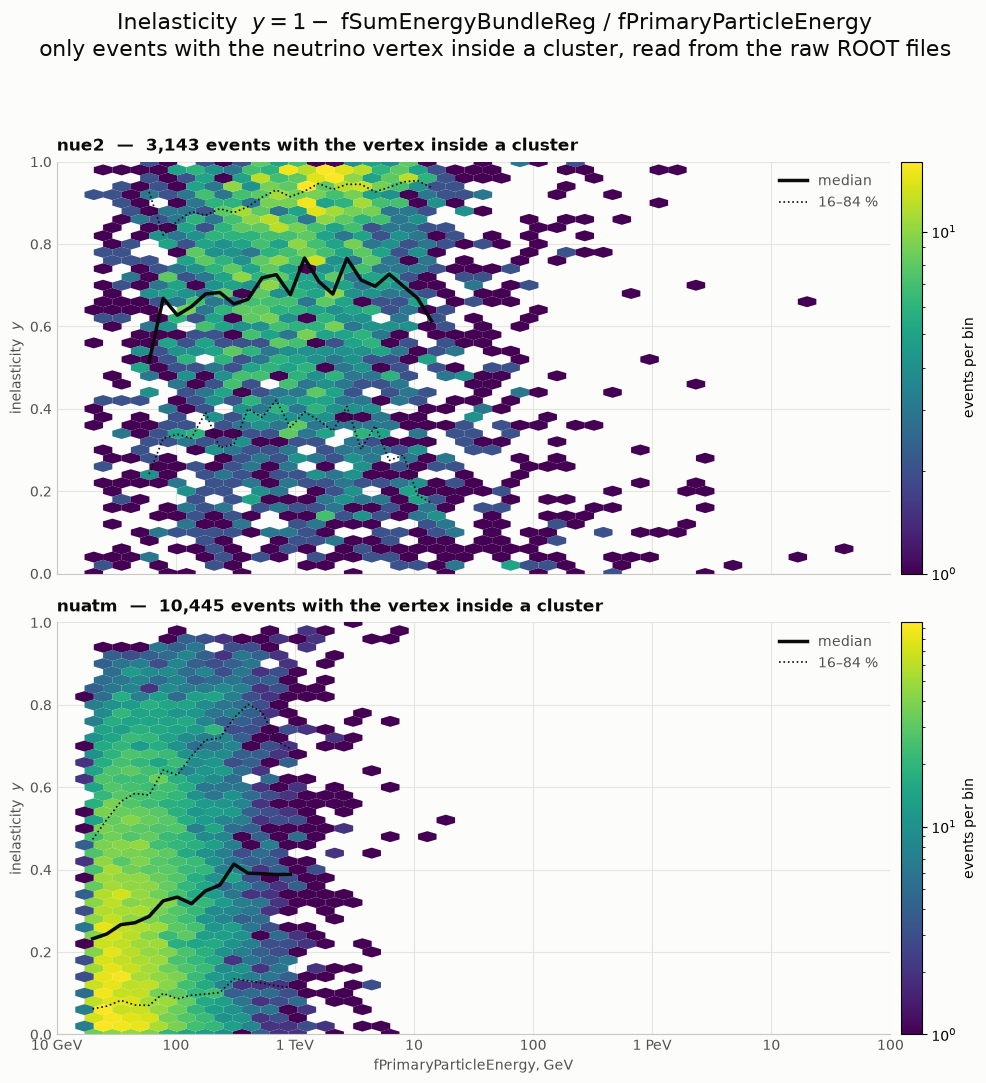

In [6]:
from matplotlib.colors import Normalize

edges = np.logspace(1, 8, 60)
centres_of_bins = 0.5 * (edges[:-1] + edges[1:])

fig, axes = plt.subplots(2, 1, figsize=(10, 11), sharex=True)
fig.patch.set_facecolor(SURFACE)

for ax, (name, (a, sel, deltas, inside)) in zip(axes, data.items()):
    e_nu = a["e_nu"][inside]
    y = (1 - a["reg"] / a["e_nu"])[inside]

    ax.set_facecolor(SURFACE)
    hb = ax.hexbin(np.log10(e_nu), y, gridsize=45, extent=(1, 8, 0, 1), cmap="viridis",
                   bins="log", mincnt=1, linewidths=0)
    fig.colorbar(hb, ax=ax, pad=0.012, fraction=0.046, label="events per bin")

    q = np.full((3, len(centres_of_bins)), np.nan)
    for k, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
        m = (e_nu >= lo) & (e_nu < hi)
        if m.sum() > 50:
            q[:, k] = np.percentile(y[m], [16, 50, 84])
    ax.plot(np.log10(centres_of_bins), q[1], color=INK, linewidth=2.5, label="median")
    ax.plot(np.log10(centres_of_bins), q[0], color=INK, linewidth=1.2, linestyle=":", label="16–84 %")
    ax.plot(np.log10(centres_of_bins), q[2], color=INK, linewidth=1.2, linestyle=":")

    ax.set_xlim(1, 8); ax.set_ylim(0, 1)
    ax.set_ylabel("inelasticity  $y$", color=MUTED)
    ax.set_title(f"{name}  —  {inside.sum():,} events with the vertex inside a cluster",
                 loc="left", fontweight="bold", color=INK, pad=8)
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#c9c8c3")
    ax.tick_params(colors=MUTED, length=0)
    ax.legend(frameon=False, labelcolor=MUTED, loc="upper right")

axes[-1].set_xticks(range(1, 9))
axes[-1].set_xticklabels(["10 GeV", "100", "1 TeV", "10", "100", "1 PeV", "10", "100"])
axes[-1].set_xlabel("fPrimaryParticleEnergy, GeV", color=MUTED)
axes[0].tick_params(labelbottom=False)
fig.suptitle("Inelasticity  $y = 1 - $ fSumEnergyBundleReg $/$ fPrimaryParticleEnergy\n"
             "only events with the neutrino vertex inside a cluster, read from the raw ROOT files",
             fontsize=16, color=INK)
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

## What the two halves of the notebook say together

Both readings come from the same two files and the same reader, so they share any defect the
reader has — but they do not share any defect of the HDF5 conversion or of the companion file.

- The cascade at the vertex is present in `nu2_100pev` and absent in `nuatm` (first half).
- The inelasticity differs by a factor 1.7–2 at every energy the two samples share: `nuatm` gives
  `y ≈ 0.28–0.44`, `nu2` gives `y ≈ 0.55–0.73` (second half).

The first difference is what the two files say about the vertex; the second is what they say about
how the energy is split. Both are properties of the generator's output, not of the reading.